<div style="text-align:center">

# Menyusun Prompt AI yang Baik untuk Permasalahan Geofisika
### Penerapan Framework R–T–C–I–K–O–Q–V pada Lima Kasus

**Nama :** [isi nama] &nbsp;&nbsp;|&nbsp;&nbsp; **NIM :** [isi NIM]

</div>

---

## 1. Pendahuluan

Dalam pekerjaan geofisika (interpretasi, inversi, pemodelan), prompt AI bukan sekadar pertanyaan singkat. Prompt berfungsi sebagai **spesifikasi kerja** (*work specification*), setara dengan *Term of Reference* (ToR) pada proyek nyata. Prompt yang baik membuat keluaran AI **dapat diaudit**: pembaca bisa menelusuri dasar setiap keputusan dan membedakan analisis berbasis data dari klaim tanpa dasar.

Struktur minimum prompt mengikuti Gambar 2.1 pada *AI Cookbook untuk Earth Sciences*:

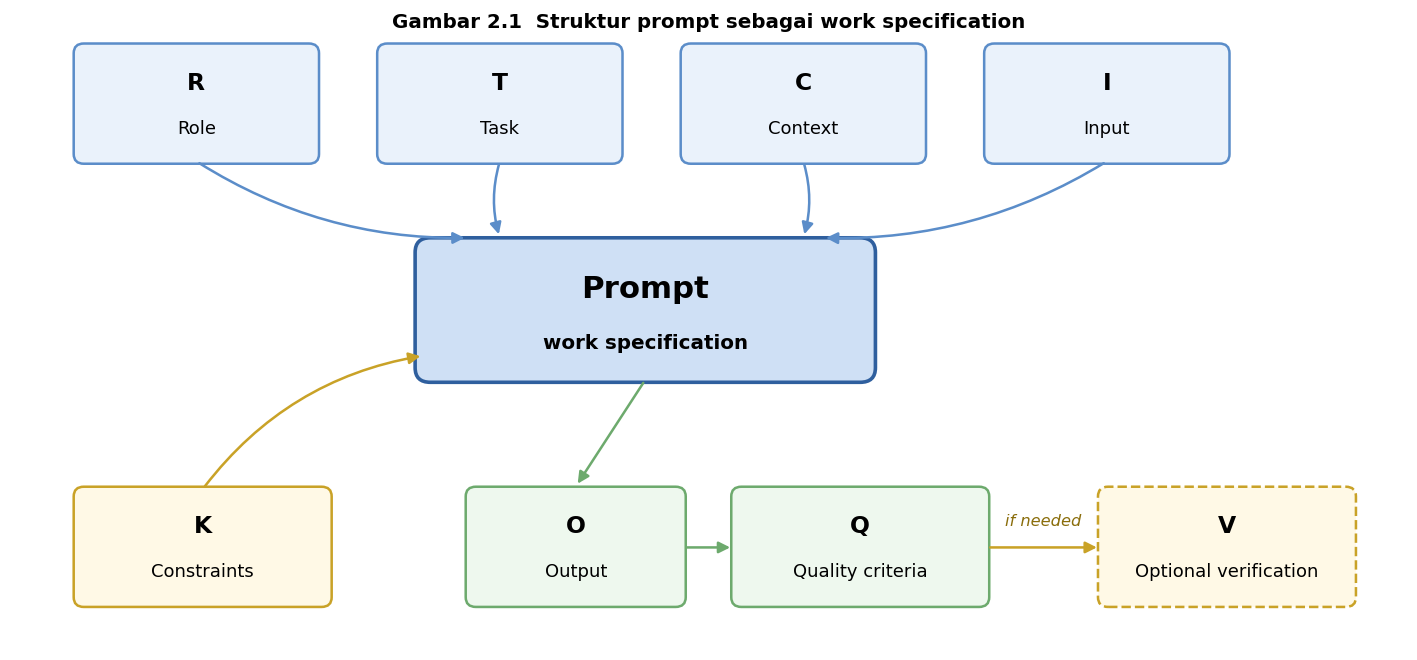

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 5.2); ax.axis("off")

BLUE  = dict(fc="#EAF2FB", ec="#5B8DC9")
CORE  = dict(fc="#CFE0F5", ec="#2F5F9E")
GREEN = dict(fc="#EEF8EE", ec="#6DAA6D")
YEL   = dict(fc="#FFF9E6", ec="#C9A227")

def box(x, y, w, h, letter, label, style, dashed=False, size=13):
    p = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                       lw=1.4, ls="--" if dashed else "-", **style)
    ax.add_patch(p)
    ax.text(x + w/2, y + h*0.68, letter, ha="center", va="center", fontsize=size, weight="bold")
    ax.text(x + w/2, y + h*0.28, label, ha="center", va="center", fontsize=10)

def arrow(p1, p2, color="#5B8DC9", rad=0.0):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=13, lw=1.4,
                                 color=color, connectionstyle=f"arc3,rad={rad}"))

# Baris atas: R, T, C, I
for x, l, t in [(0.5, "R", "Role"), (2.9, "T", "Task"), (5.3, "C", "Context"), (7.7, "I", "Input")]:
    box(x, 4.0, 1.9, 0.95, l, t, BLUE)

# Inti: Prompt
core = FancyBboxPatch((3.2, 2.2), 3.6, 1.15, boxstyle="round,pad=0.02,rounding_size=0.12",
                      lw=2, **CORE)
ax.add_patch(core)
ax.text(5.0, 2.95, "Prompt", ha="center", va="center", fontsize=17, weight="bold")
ax.text(5.0, 2.5, "work specification", ha="center", va="center", fontsize=11, weight="bold")

for cx in (1.45, 3.85, 6.25, 8.65):
    tx = min(max(cx, 3.6), 6.4)
    arrow((cx, 4.0), (tx, 3.37), rad=0.15 if cx < 5 else -0.15)

# Constraints
box(0.5, 0.35, 2.0, 0.95, "K", "Constraints", YEL)
arrow((1.5, 1.3), (3.25, 2.4), color="#C9A227", rad=-0.2)

# Output, Quality, Verification
box(3.6, 0.35, 1.7, 0.95, "O", "Output", GREEN)
box(5.7, 0.35, 2.0, 0.95, "Q", "Quality criteria", GREEN)
box(8.6, 0.35, 2.0, 0.95, "V", "Optional verification", YEL, dashed=True)

arrow((5.0, 2.2), (4.45, 1.32), color="#6DAA6D")
arrow((5.3, 0.82), (5.7, 0.82), color="#6DAA6D")
arrow((7.7, 0.82), (8.6, 0.82), color="#C9A227")
ax.text(8.15, 1.0, "if needed", ha="center", fontsize=9, style="italic", color="#8A6D0B")

ax.text(5.5, 5.1, "Gambar 2.1  Struktur prompt sebagai work specification", ha="center", fontsize=11, weight="bold")
plt.tight_layout(); plt.show()

**R, T, C, I, K** membentuk *spesifikasi pekerjaan* (apa yang dikerjakan dan batasannya), sedangkan **O, Q, (V)** membentuk *deliverable* (apa yang dihasilkan, kriteria penerimaannya, dan verifikasi bila diperlukan).

## 2. Komponen Framework

| Huruf | Komponen | Pertanyaan yang dijawab | Contoh dalam geofisika |
|:---:|---|---|---|
| **R** | Role | Siapa yang AI perankan? | Geofisikawan eksplorasi dengan keahlian metode tertentu |
| **T** | Task | Apa yang harus dikerjakan? | Kata kerja terukur: *interpretasikan, hitung, delineasi* |
| **C** | Context | Apa latar belakang masalahnya? | Lokasi, geometri survei, kondisi geologi, tujuan studi |
| **I** | Input | Data apa yang tersedia? | Format file, kolom, satuan, jumlah titik |
| **K** | Constraints | Apa yang tidak boleh dilanggar? | Dilarang mengarang data, metode wajib, istilah "indikasi" |
| **O** | Output | Dalam bentuk apa hasilnya? | Struktur laporan naratif, tabel, urutan bagian |
| **Q** | Quality criteria | Kapan hasil dinyatakan layak? | Setiap klaim merujuk angka, satuan konsisten, ketidakpastian dinyatakan |
| **V** | Verification *(opsional)* | Bagaimana hasil diuji? | Korelasi data bor/sumur, uji sensitivitas, cek residual |

## 3. Lima Prompt Geofisika

Setiap prompt di bawah ini ditulis sebagai **spesifikasi kerja** yang lengkap. Bagian ini berhenti pada prompt; *hasil (output) AI belum dibuat*. Nilai angka pada bagian Context adalah contoh skenario.

| No | Kasus | Metode | Fokus kontrol utama |
|:---:|---|---|---|
| 1 | Zona mineralisasi sulfida | ERT + IP | Membedakan anomali sejati dari artefak inversi |
| 2 | Intrusi air laut di pesisir | ERT | Ambang resistivitas eksplisit, ambiguitas lempung |
| 3 | Intrusi ultramafik | Magnetik | Reduksi ke kutub di lintang rendah |
| 4 | Struktur cekungan sedimen | Gravitasi | Rantai koreksi yang dapat ditelusuri |
| 5 | Kedalaman batuan dasar untuk pondasi | Seismik refraksi | Batas metode: lapisan tersembunyi |

---

### Prompt 1 — Interpretasi ERT + IP untuk Zona Mineralisasi Sulfida

> **R — Role**
>
> Anda adalah geofisikawan eksplorasi mineral senior yang berpengalaman menginterpretasi hasil inversi resistivitas dan *chargeability*, serta memahami alur kerja inversi geolistrik dengan pyGIMLi.
>
> **T — Task**
>
> Interpretasikan hasil inversi 2D data ERT dan IP pada satu lintasan, identifikasi zona anomali yang berindikasi mineralisasi sulfida (resistivitas rendah dengan *chargeability* tinggi), jelaskan dasar geofisisnya, lalu susun rekomendasi titik pemboran verifikasi.
>
> **C — Context**
>
> Survei dilakukan pada lintasan 200 m dengan 41 elektroda (spasi 5 m) berkonfigurasi Wenner–Schlumberger. Area diduga memiliki sulfida terdiseminasi pada batuan vulkanik terubah. Inversi 2D dijalankan di pyGIMLi dengan RMS error di bawah 5%. Hasil dipakai untuk menentukan target pemboran tahap awal.
>
> **I — Input**
>
> - Berkas resistivitas hasil inversi (`.txt`/`.vtk`): kolom *x*, *z*, ρ (Ωm)
> - Berkas *chargeability* hasil inversi: kolom *x*, *z*, M (mV/V)
> - Metadata inversi: kedalaman investigasi maksimum, RMS, jumlah iterasi, parameter regularisasi
>
> **K — Constraints**
>
> - Interpretasi hanya boleh bersumber dari data yang diberikan; jangan mengasumsikan data yang tidak ada (mis. litologi bor).
> - Jangan mengubah atau memperkirakan ulang nilai ρ dan M tanpa keterangan eksplisit.
> - Gunakan satuan baku: Ωm dan mV/V.
> - Gunakan istilah "indikasi" atau "potensi"; jangan menyebut jenis mineral, kadar, atau tonase secara pasti.
> - Bedakan anomali nyata dari kemungkinan artefak (tepi model, zona sensitivitas rendah).
>
> **O — Output**
>
> Laporan naratif dengan urutan berikut:
> 1. Ringkasan kondisi geolistrik lintasan (rentang ρ dan M)
> 2. Tabel anomali: ID, posisi jarak, kedalaman, nilai ρ, nilai M
> 3. Interpretasi geologi/mineralisasi beserta tingkat keyakinan (tinggi/sedang/rendah) dan alasannya
> 4. Keterbatasan data dan interpretasi
> 5. Rekomendasi titik bor lanjutan berurutan prioritas
>
> **Q — Quality Criteria**
>
> - Setiap klaim merujuk pada nilai numerik dari data input.
> - Posisi anomali ρ dan M dirujuk silang dan konsisten.
> - Penjelasan alternatif (mis. zona lempung: ρ rendah, M sedang) dibahas sebelum simpulan.
> - Tidak ada informasi di luar data yang diberikan.
>
> **V — Optional Verification**
>
> Bila tersedia, bandingkan posisi anomali dengan geologi permukaan atau data bor terdekat. Uji juga apakah anomali utama berada di dalam batas kedalaman investigasi dan sensitivitas model.

---

### Prompt 2 — Delineasi Intrusi Air Laut dengan ERT

> **R — Role**
>
> Anda adalah hidrogeofisikawan yang berpengalaman menggunakan metode geolistrik untuk memetakan salinitas air tanah di wilayah pesisir.
>
> **T — Task**
>
> Interpretasikan hasil inversi ERT 2D pada tiga lintasan, klasifikasikan zona air tawar, payau, dan asin berdasarkan resistivitas, lalu tentukan posisi antarmuka air tawar–air asin serta perubahannya terhadap jarak dari garis pantai.
>
> **C — Context**
>
> Area pesisir dengan akuifer aluvial berupa pasir berselingan lempung. Warga melaporkan air sumur menjadi payau pada musim kemarau. Tiga lintasan sepanjang 300 m (spasi elektroda 5 m, konfigurasi Wenner) dibuat tegak lurus garis pantai. Tujuan studi: mengetahui sejauh mana intrusi menjangkau daratan.
>
> **I — Input**
>
> - Tiga berkas hasil inversi: *x*, *z*, ρ (Ωm), RMS per lintasan
> - Jarak awal tiap lintasan dari garis pantai (m)
> - Data daya hantar listrik (DHL, µS/cm) pada sumur warga, bila tersedia, beserta kedalaman sumur
>
> **K — Constraints**
>
> - Ambang resistivitas tiap kelas (tawar/payau/asin) harus dinyatakan sebagai **asumsi** beserta alasannya, bukan sebagai nilai baku.
> - Gunakan ambang yang sama pada ketiga lintasan.
> - Jangan mengonversi resistivitas menjadi salinitas (mg/L) tanpa data kalibrasi.
> - Jangan mengarang data sumur yang tidak diberikan.
> - Sebutkan ambiguitas: lempung jenuh air dapat memiliki resistivitas rendah serupa air asin.
>
> **O — Output**
>
> Laporan naratif dengan urutan berikut:
> 1. Ringkasan tiap lintasan (rentang ρ, kedalaman investigasi)
> 2. Tabel klasifikasi zona: kelas, rentang ρ, sebaran jarak dan kedalaman
> 3. Posisi antarmuka air tawar–air asin terhadap jarak dari pantai
> 4. Perbandingan tren antar lintasan
> 5. Rekomendasi pemantauan (titik sumur pantau, survei ulang)
>
> **Q — Quality Criteria**
>
> - Ambang klasifikasi konsisten antar lintasan.
> - Setiap zona disertai rentang ρ dan tingkat keyakinan.
> - Zona yang ambigu (lempung vs air asin) ditandai jelas.
> - Seluruh klaim dapat ditelusuri ke nilai numerik pada data input.
>
> **V — Optional Verification**
>
> Bandingkan hasil klasifikasi dengan DHL sumur pada kedalaman yang sesuai. Bila ada survei ulang (*time-lapse*), periksa apakah antarmuka bergeser searah dengan dugaan musiman.

---

### Prompt 3 — Analisis Anomali Magnetik untuk Intrusi Ultramafik

> **R — Role**
>
> Anda adalah geofisikawan metode potensial (magnetik) yang berpengalaman dalam eksplorasi batuan ultramafik dan pemetaan struktur.
>
> **T — Task**
>
> Lakukan *quality control* data, koreksi variasi harian dan IGRF, reduksi ke kutub, lalu interpretasikan secara kualitatif anomali medan magnet total untuk mengidentifikasi tubuh sumber dan lineamen struktur.
>
> **C — Context**
>
> Survei magnetik darat seluas ± 1,5 × 1,5 km dengan jarak antar lintasan 50 m dan jarak antar titik 10 m. Lokasi berada di lintang rendah Sulawesi. Area diduga mengandung tubuh ultramafik yang berasosiasi dengan potensi nikel laterit. Tujuan studi: menetapkan batas tubuh ultramafik dan zona struktur untuk perencanaan pengeboran.
>
> **I — Input**
>
> - Berkas CSV: *x*, *y* (UTM), medan magnet total (nT), waktu pengukuran
> - Data *base station* harian (nT terhadap waktu)
> - Parameter IGRF lokasi: deklinasi, inklinasi, nilai medan referensi
>
> **K — Constraints**
>
> - Tulis setiap tahap koreksi berikut besaran dan rentang koreksinya; jangan melewatkan tahap tanpa keterangan.
> - Jangan menambah atau menghapus titik data tanpa alasan tertulis.
> - Nyatakan bahwa reduksi ke kutub pada lintang rendah rentan menghasilkan artefak dan jelaskan cara menyikapinya (mis. RTP variabel, *analytic signal*).
> - Jangan menyebut kedalaman atau geometri tubuh sebagai pasti; gunakan "perkiraan" atau "indikasi".
>
> **O — Output**
>
> Laporan naratif dengan urutan berikut:
> 1. Hasil QC data dan ringkasan koreksi (rentang, satuan)
> 2. Statistik anomali (minimum, maksimum, rata-rata, sebaran)
> 3. Tabel anomali: ID, posisi, amplitudo (nT), pola (dipolar/monopolar)
> 4. Interpretasi tubuh sumber dan lineamen struktur beserta tingkat keyakinan
> 5. Keterbatasan dan saran survei atau pemodelan lanjutan (mis. pemodelan 2,5D)
>
> **Q — Quality Criteria**
>
> - Seluruh besaran dalam nT dan tercatat pada tiap tahap koreksi.
> - Interpretasi pada peta anomali dan peta hasil RTP tidak saling bertentangan; bila berbeda, dijelaskan.
> - Setiap klaim merujuk pada amplitudo atau posisi yang tercantum di tabel.
> - Ketidakpastian akibat lintang rendah dinyatakan secara eksplisit.
>
> **V — Optional Verification**
>
> Periksa *crossover error* antar lintasan, uji kestabilan anomali dengan *upward continuation*, dan bandingkan lineamen dengan peta geologi atau kelurusan citra DEM.

---

### Prompt 4 — Anomali Bouguer dan Struktur Cekungan Sedimen

> **R — Role**
>
> Anda adalah geofisikawan gravitasi yang berpengalaman dalam pengolahan data gravimeter lapangan dan interpretasi struktur bawah permukaan.
>
> **T — Task**
>
> Hitung anomali Bouguer lengkap dari data gravitasi lapangan melalui rantai koreksi yang terdokumentasi, pisahkan anomali regional dan residual, lalu interpretasikan batas cekungan dan kemungkinan sesar.
>
> **C — Context**
>
> Survei gravitasi di cekungan sedimen kecil dengan 120 titik ukur, gravimeter Scintrex CG-5, dan pengukuran secara *looping* terhadap satu titik base. Densitas reduksi standar 2,67 g/cm³. Tujuan studi: memetakan geometri cekungan dan zona sesar sebagai dasar pemodelan lanjutan.
>
> **I — Input**
>
> - Berkas CSV: ID titik, lintang, bujur, elevasi (m), bacaan gravimeter (mGal), waktu
> - Data base dan tinggi alat
> - Data DEM (resolusi 30 m) untuk koreksi medan
>
> **K — Constraints**
>
> - Sebutkan rumus dan parameter tiap koreksi: *drift*, pasang surut, lintang, udara bebas, Bouguer, medan.
> - Densitas reduksi harus dinyatakan; jangan mengubahnya tanpa alasan dan tanpa uji.
> - Metode pemisahan regional–residual harus disebut beserta alasan pemilihannya.
> - Jangan mengarang titik atau nilai gravitasi yang tidak ada di data.
> - Nyatakan bahwa solusi model gravitasi tidak unik.
>
> **O — Output**
>
> Laporan naratif dengan urutan berikut:
> 1. Ringkasan QC dan penutupan *loop* (*drift*)
> 2. Tabel tahapan koreksi: rentang tiap koreksi dalam mGal
> 3. Statistik anomali Bouguer lengkap
> 4. Uraian anomali residual dan pola kontur (gradien, kelurusan, minimum)
> 5. Interpretasi batas cekungan dan sesar beserta keterbatasan
>
> **Q — Quality Criteria**
>
> - Satuan mGal konsisten pada seluruh tahap.
> - Besaran koreksi wajar secara fisik (mis. koreksi udara bebas sekitar 0,3086 mGal per meter).
> - Setiap tahap dapat ditelusuri sehingga hasil dapat direproduksi.
> - Interpretasi struktural dikaitkan dengan gradien nilai anomali yang disebutkan secara numerik.
>
> **V — Optional Verification**
>
> Lakukan uji sensitivitas terhadap densitas reduksi (mis. metode Nettleton), bandingkan tren regional dengan model gravitasi global, dan cocokkan batas cekungan dengan peta geologi.

---

### Prompt 5 — Kedalaman Batuan Dasar dengan Seismik Refraksi

> **R — Role**
>
> Anda adalah geofisikawan seismik dangkal untuk keperluan geoteknik yang berpengalaman dalam interpretasi kurva waktu tempuh gelombang P.
>
> **T — Task**
>
> Tentukan jumlah lapisan dan kecepatan gelombang P tiap lapisan dari data *first-break*, hitung kedalaman bidang batas menggunakan metode *intercept-time*, lalu tentukan kedalaman batuan dasar di bawah lintasan.
>
> **C — Context**
>
> Survei untuk rencana pondasi bangunan. *Spread* 24 geophone berspasi 2 m, dengan *shot* maju, *shot* balik, dan *shot* tengah. Kondisi diduga berupa tanah lapuk di atas batuan yang lebih kompak. Hasil dipakai untuk memilih tipe dan kedalaman pondasi.
>
> **I — Input**
>
> - Tabel *first-break*: *offset* (m) dan waktu tiba (ms) untuk tiap *shot*
> - Koordinat dan elevasi *shot* serta geophone
>
> **K — Constraints**
>
> - Nyatakan metode hitung yang dipakai dan rumusnya.
> - Penentuan jumlah lapisan harus berdasarkan perubahan kemiringan kurva waktu tempuh, bukan asumsi.
> - Jangan mengasumsikan kecepatan yang tidak dapat diturunkan dari data.
> - Nyatakan keterbatasan metode: lapisan tersembunyi (*hidden layer*) dan inversi kecepatan tidak terdeteksi.
> - Klasifikasi kekerasan batuan hanya berdasarkan kecepatan, dengan menyebut acuan yang dipakai.
>
> **O — Output**
>
> Laporan naratif dengan urutan berikut:
> 1. Ringkasan kualitas data dan kurva waktu tempuh
> 2. Tabel model: lapisan, kecepatan Vp (m/s), ketebalan, kedalaman bidang batas
> 3. Interpretasi litologi dan kedalaman batuan dasar
> 4. Ketidakpastian dan keterbatasan
> 5. Implikasi untuk pemilihan pondasi
>
> **Q — Quality Criteria**
>
> - Kecepatan hasil *shot* maju dan balik konsisten (koreksi kemiringan dijelaskan).
> - Perhitungan kedalaman ditampilkan sehingga dapat diperiksa.
> - Ketidakpastian (±) disebut untuk kecepatan dan kedalaman.
> - Simpulan tidak melampaui kemampuan data.
>
> **V — Optional Verification**
>
> Periksa *reciprocal time* antara *shot* maju dan balik, lalu bandingkan kedalaman batuan dasar dengan log bor atau uji SPT/sondir terdekat.

---

## 4. Mengapa Kelima Prompt Ini Dianggap Baik

| Komponen | Yang dilakukan pada kelima prompt | Manfaat |
|---|---|---|
| **Role** | Menentukan keahlian metode tertentu | Tingkat teknis jawaban sesuai kebutuhan |
| **Task** | Memakai kata kerja terukur (*interpretasikan, hitung, delineasi, tentukan*) | Hasil dapat dinilai tuntas atau tidak |
| **Context** | Memuat geometri survei, kondisi geologi, dan tujuan studi | Interpretasi tidak generik |
| **Input** | Menyebut format berkas, kolom, dan satuan | AI tahu data apa yang dapat diolah |
| **Constraints** | Melarang mengarang data dan memaksa istilah "indikasi" | Mencegah klaim berlebihan dan halusinasi |
| **Output** | Menetapkan urutan bagian laporan | Hasil terstruktur dan mudah diperiksa |
| **Quality** | Mensyaratkan rujukan angka, konsistensi, dan ketidakpastian | Tolok ukur objektif terima atau tolak |
| **Verification** | Menautkan hasil dengan data pembanding | Validitas dapat diuji |

## 5. Template Kosong

Salin dan isi untuk kasus geofisika lain:

```text
R — Role
[Peran dan keahlian spesifik]

T — Task
[Tugas dengan kata kerja terukur]

C — Context
[Lokasi, metode, geometri survei, kondisi geologi, tujuan studi]

I — Input
[Berkas/data, format, kolom, satuan]

K — Constraints
[Asumsi yang boleh/tidak boleh, metode wajib, larangan mengarang data]

O — Output
[Struktur laporan berurutan]

Q — Quality Criteria
[Kriteria agar hasil diterima]

V — Optional Verification
[Cara menguji hasil]
```

## 6. Catatan Penutup

Framework dapat diringkas bila detail sudah tersimpan pada *configuration* atau *recipe* pendamping, misalnya template proyek yang baku. Namun **kontrak kerja tidak boleh hilang**, sehingga **Constraints** dan **Quality Criteria** tetap wajib ada meski prompt dipersingkat.